In [1]:
import cv2
import numpy as np
import random

def augment_3dprint_image(img):
    """
    Applies random lightweight augmentation to a single 3D printer image.
    Includes:
      - Low-cost geometric transforms (rotation, translation, scale)
      - Low-cost noise injection (Gaussian noise, blur)
    
    Args:
        img (np.ndarray): Input image read with cv2.imread (BGR format)
    
    Returns:
        np.ndarray: Augmented image (same shape as input)
    """
    aug_img = img.copy()
    h, w = aug_img.shape[:2]
    
    # ------------------------
    # 1. Random rotation (-10 to +10 degrees)
    # ------------------------
    angle = random.uniform(-10, 10)
    M_rot = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
    aug_img = cv2.warpAffine(aug_img, M_rot, (w, h), borderMode=cv2.BORDER_REFLECT)
    
    # ------------------------
    # 2. Random translation (-10% to +10% of width/height)
    # ------------------------
    tx = random.uniform(-0.1*w, 0.1*w)
    ty = random.uniform(-0.1*h, 0.1*h)
    M_trans = np.float32([[1, 0, tx], [0, 1, ty]])
    aug_img = cv2.warpAffine(aug_img, M_trans, (w, h), borderMode=cv2.BORDER_REFLECT)
    
    # ------------------------
    # 3. Random scaling (0.9 to 1.1)
    # ------------------------
    scale = random.uniform(0.9, 1.1)
    aug_img = cv2.resize(aug_img, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
    
    # Crop or pad back to original size
    new_h, new_w = aug_img.shape[:2]
    if new_h > h:
        start_h = (new_h - h)//2
        aug_img = aug_img[start_h:start_h+h, :]
    elif new_h < h:
        pad_h = h - new_h
        aug_img = cv2.copyMakeBorder(aug_img, pad_h//2, pad_h - pad_h//2, 0, 0, cv2.BORDER_REFLECT)
    
    if new_w > w:
        start_w = (new_w - w)//2
        aug_img = aug_img[:, start_w:start_w+w]
    elif new_w < w:
        pad_w = w - new_w
        aug_img = cv2.copyMakeBorder(aug_img, 0, 0, pad_w//2, pad_w - pad_w//2, cv2.BORDER_REFLECT)
    
    # ------------------------
    # 4. Random Gaussian noise
    # ------------------------
    if random.random() < 0.5:  # 50% chance to add noise
        sigma = random.uniform(5, 20)  # standard deviation
        gauss = np.random.normal(0, sigma, aug_img.shape).astype(np.float32)
        aug_img = aug_img.astype(np.float32) + gauss
        aug_img = np.clip(aug_img, 0, 255).astype(np.uint8)
    
    # ------------------------
    # 5. Optional light Gaussian blur
    # ------------------------
    if random.random() < 0.3:  # 30% chance to blur
        ksize = random.choice([1, 3])  # small kernel
        if ksize > 1:
            aug_img = cv2.GaussianBlur(aug_img, (ksize, ksize), 0)
    
    return aug_img


In [2]:
# Read image
"""img = cv2.imread("test.jpg")

# Apply stringing augmentation
aug_img = augment_3dprint_image(img)

# Show result
cv2.imshow("Original", img)
cv2.imshow("Augmented - Stringing", aug_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

# Optionally save
cv2.imwrite("augmented_stringing.jpg", aug_img)"""


'img = cv2.imread("test.jpg")\n\n# Apply stringing augmentation\naug_img = augment_3dprint_image(img)\n\n# Show result\ncv2.imshow("Original", img)\ncv2.imshow("Augmented - Stringing", aug_img)\ncv2.waitKey(0)\ncv2.destroyAllWindows()\n\n# Optionally save\ncv2.imwrite("augmented_stringing.jpg", aug_img)'

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.datasets import ImageFolder
from PIL import Image
import os

# ------------------------
# 1. Device
# ------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------
# 2. Dataset transforms
# ------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5], [0.5,0.5,0.5])
])

# ------------------------
# 3. Training dataset & loader
# ------------------------
train_dir = "dataset/train"
train_dataset = ImageFolder(root=train_dir, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True, num_workers=6)

# ------------------------
# 5. Define a lightweight MobileViT-like model (offline)
# ------------------------
# این مدل بسیار سبک است و شبیه MobileViT عمل می‌کند
class MiniMobileViT(nn.Module):
    def __init__(self, num_classes=2):
        super(MiniMobileViT, self).__init__()
        # ساده سازی با conv+linear
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, stride=2, padding=1),  # 224 -> 112
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1),  # 112 -> 56
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),  # 56 -> 28
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.classifier = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x



In [ ]:
model = MiniMobileViT(num_classes=2).to(device)

# ------------------------
# 6. Loss and optimizer
# ------------------------
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# ------------------------
# 7. Training loop
# ------------------------
num_epochs = 15
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    train_loss = running_loss / total
    train_acc = correct / total * 100
    print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {train_loss:.4f}, Acc: {train_acc:.2f}%")

# ------------------------
# 8. Save model
# ------------------------
torch.save(model.state_dict(), "minimobilevit_3dprinter.pth")
print("Model saved!")


# ٍEvaluation Phase

In [ ]:
import torch as tr

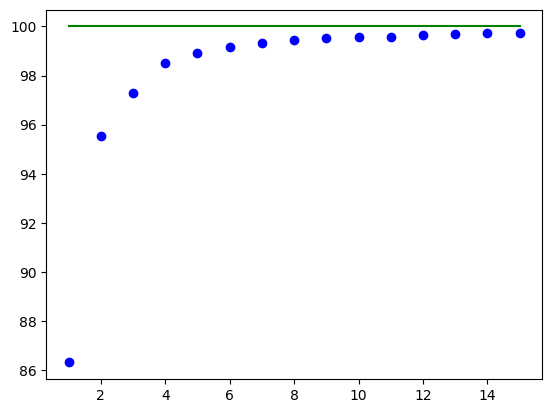

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline
epochs = [i for i in range(1,16)]
losses = [0.2937, 0.1147, 0.0715, 0.0424, 0.0299, 0.0249, 0.0192, 0.0160, 0.0138, 0.0130, 0.0117, 0.0099, 0.0089, 0.0081, 0.0078]
accuracies = [86.31, 95.52, 97.29, 98.51, 98.90, 99.15, 99.32, 99.44, 99.55, 99.56, 99.58, 99.65, 99.69, 99.73, 99.73]
complete_x = []
num_epochs = 15
for i in range(num_epochs):
    complete_x.append(100.0)
plt.plot(epochs, complete_x, c="g")
plt.scatter(epochs, accuracies, c="b")
plt.show()

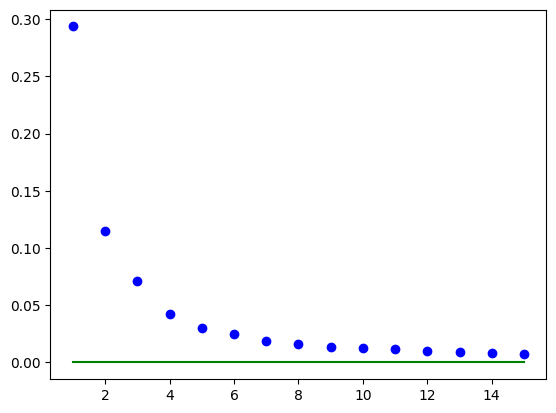

In [ ]:
plt.plot(epochs, [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0], c="g")
plt.scatter(epochs, losses, c="b")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix

device = tr.device("cuda" if tr.cuda.is_available() else "cpu")
loaded_model = MiniMobileViT()
loaded_model.load_state_dict(tr.load("minimobilevit_3dprinter.pth",map_location=device))

<All keys matched successfully>

In [ ]:
from torch.utils.data import Dataset
from PIL import Image
import pandas as pd
import os


class TestDataset(Dataset):
    def __init__(self, root, csv_path, transform=None):
        self.root = root
        self.transform = transform

        df = pd.read_csv(csv_path)

        # مسیر کامل مورد نیاز Kaggle
        self.rel_paths = df["img_path"].values

        # فقط نام فایل واقعی روی دیسک
        self.filenames = [os.path.basename(p) for p in self.rel_paths]

    def __len__(self):
        return len(self.rel_paths)

    def __getitem__(self, idx):
        filename = self.filenames[idx]
        rel_path = self.rel_paths[idx]

        full_path = os.path.join(self.root, filename)

        img = Image.open(full_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        # 🔥 مهم: rel_path برای submission نگه می‌داریم
        return img, rel_path

test_dir = "dataset/test"
csv_path = "dataset/sample_submission.csv"

test_dataset = TestDataset(
    root=test_dir,
    csv_path=csv_path,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

torch.set_num_threads(os.cpu_count())

loaded_model.eval()

all_preds = []
all_img_paths = []

with torch.inference_mode():
    for images, rel_paths in tqdm(test_loader):
        images = images.to(device)

        outputs = loaded_model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_img_paths.extend(rel_paths)

print("Inference done ✅")

submission_df = pd.DataFrame({
    "img_path": all_img_paths,
    "has_under_extrusion": all_preds
})

submission_df.to_csv("submission.csv", index=False)

print("Submission file saved ✅")

100%|██████████| 790/790 [01:35<00:00,  8.28it/s]


Inference done ✅
Submission file saved ✅


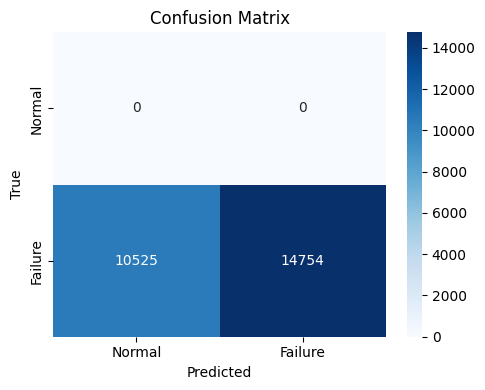

In [51]:
import seaborn as sns

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal","Failure"],
            yticklabels=["Normal","Failure"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds)
rec = recall_score(all_labels, all_preds)
f1 = f1_score(all_labels, all_preds)

table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [acc, prec, rec, f1]
})

print(table)
table.to_csv("performance_table.csv", index=False)

      Metric     Value
0   Accuracy  0.583647
1  Precision  1.000000
2     Recall  0.583647
3   F1-score  0.737092


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms, datasets
from sklearn.model_selection import GroupKFold
import numpy as np
import os

# ------------------------
# 1. Device (CPU only)
# ------------------------
device = torch.device("cpu")

# ------------------------
# 2. Dataset transforms
# ------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5], [0.5,0.5,0.5])
])

# ------------------------
# 3. Dataset
# ------------------------
train_dir = "dataset/train"
dataset = datasets.ImageFolder(root=train_dir, transform=transform)

# ------------------------
# 4. Extract video groups
# ------------------------
# Assumes folder structure: train/class_x/video1_frame001.jpg
# We parse video name from the file path
video_ids = []
for path, _ in dataset.samples:
    # example: dataset/train/class0/video1_frame001.jpg
    folder = os.path.basename(os.path.dirname(path))  # class folder
    filename = os.path.basename(path)
    # take first part before '_' as video id
    video_id = filename.split('_')[0]  # e.g., video1
    video_ids.append(video_id)

video_ids = np.array(video_ids)
labels = np.array([label for _, label in dataset.samples])

# ------------------------
# 5. Group K-Fold
# ------------------------
k_folds = 5
gkf = GroupKFold(n_splits=k_folds)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(np.zeros(len(labels)), labels, groups=video_ids)):
    print(f"\n===== FOLD {fold+1} =====")

    train_subset = Subset(dataset, train_idx)
    val_subset   = Subset(dataset, val_idx)

    train_loader = DataLoader(train_subset, batch_size=16, shuffle=True, num_workers=0)
    val_loader   = DataLoader(val_subset, batch_size=16, shuffle=False, num_workers=0)

    # ------------------------
    # 6. Define model (re-initialize per fold)
    # ------------------------
    class MiniMobileViT(nn.Module):
        def __init__(self, num_classes=2):
            super(MiniMobileViT, self).__init__()
            self.features = nn.Sequential(
                nn.Conv2d(3, 16, 3, stride=2, padding=1),
                nn.BatchNorm2d(16),
                nn.ReLU(),
                nn.Conv2d(16, 32, 3, stride=2, padding=1),
                nn.BatchNorm2d(32),
                nn.ReLU(),
                nn.Conv2d(32, 64, 3, stride=2, padding=1),
                nn.BatchNorm2d(64),
                nn.ReLU(),
                nn.AdaptiveAvgPool2d((1,1))
            )
            self.classifier = nn.Linear(64, num_classes)
        
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
            x = self.classifier(x)
            return x

    model = MiniMobileViT(num_classes=2).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    # ------------------------
    # 7. Training loop
    # ------------------------
    num_epochs = 10  # keep small for CPU
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        for images, labels_batch in train_loader:
            images, labels_batch = images.to(device), labels_batch.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels_batch.size(0)
            correct += predicted.eq(labels_batch).sum().item()
        train_loss = running_loss / total
        train_acc = correct / total * 100

        # Validation
        model.eval()
        val_correct = 0
        val_total = 0
        val_loss = 0.0
        with torch.no_grad():
            for images, labels_batch in val_loader:
                images, labels_batch = images.to(device), labels_batch.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels_batch)
                val_loss += loss.item() * images.size(0)
                _, predicted = outputs.max(1)
                val_total += labels_batch.size(0)
                val_correct += predicted.eq(labels_batch).sum().item()
        val_loss /= val_total
        val_acc = val_correct / val_total * 100

        print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

    fold_results.append({
        "fold": fold+1,
        "train_acc": train_acc,
        "val_acc": val_acc,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

# ------------------------
# 8. Summary table
# ------------------------
import pandas as pd
df = pd.DataFrame(fold_results)
print("\n=== K-Fold Results ===")
print(df)
print(f"\nMean Val Accuracy: {df['val_acc'].mean():.2f}% ± {df['val_acc'].std():.2f}%")


===== FOLD 1 =====
Epoch [1/10] | Train Loss: 0.3133, Train Acc: 86.12% | Val Loss: 0.1547, Val Acc: 94.68%
Epoch [2/10] | Train Loss: 0.1542, Train Acc: 93.95% | Val Loss: 0.0963, Val Acc: 96.71%
Epoch [3/10] | Train Loss: 0.1047, Train Acc: 96.22% | Val Loss: 0.0582, Val Acc: 98.22%
Epoch [4/10] | Train Loss: 0.0794, Train Acc: 97.21% | Val Loss: 0.0600, Val Acc: 98.08%
Epoch [5/10] | Train Loss: 0.0600, Train Acc: 97.89% | Val Loss: 0.0511, Val Acc: 98.37%
Epoch [6/10] | Train Loss: 0.0509, Train Acc: 98.30% | Val Loss: 0.0334, Val Acc: 98.99%
Epoch [7/10] | Train Loss: 0.0420, Train Acc: 98.66% | Val Loss: 0.0402, Val Acc: 98.71%
Epoch [8/10] | Train Loss: 0.0361, Train Acc: 98.82% | Val Loss: 0.0418, Val Acc: 98.54%
Epoch [9/10] | Train Loss: 0.0304, Train Acc: 98.99% | Val Loss: 0.0337, Val Acc: 98.82%
Epoch [10/10] | Train Loss: 0.0273, Train Acc: 99.13% | Val Loss: 0.0391, Val Acc: 98.54%

===== FOLD 2 =====
Epoch [1/10] | Train Loss: 0.3055, Train Acc: 86.23% | Val Loss: 0.54

In [4]:
import torch as tr
tr.save(model.state_dict(), "mynewmodel.pt")

In [1]:
import numpy as np

# Each list = per epoch (10 epochs)

folds = {
    1: {
        "train_acc": [86.12,93.95,96.22,97.21,97.89,98.30,98.66,98.82,98.99,99.13],
        "val_acc":   [94.68,96.71,98.22,98.08,98.37,98.99,98.71,98.54,98.82,98.54],
        "train_loss":[0.3133,0.1542,0.1047,0.0794,0.0600,0.0509,0.0420,0.0361,0.0304,0.0273],
        "val_loss":  [0.1547,0.0963,0.0582,0.0600,0.0511,0.0334,0.0402,0.0418,0.0337,0.0391],
    },
    2: {
        "train_acc":[86.23,94.25,96.37,97.46,98.15,98.51,98.73,98.86,98.94,99.08],
        "val_acc":[79.76,97.18,98.42,97.93,99.05,97.63,99.15,98.51,98.14,99.40],
        "train_loss":[0.3055,0.1500,0.1010,0.0730,0.0573,0.0468,0.0398,0.0354,0.0320,0.0281],
        "val_loss":[0.5453,0.0906,0.0557,0.0675,0.0311,0.0776,0.0250,0.0428,0.0498,0.0192],
    },
    3: {
        "train_acc":[85.99,93.96,96.08,97.36,98.01,98.31,98.63,98.86,99.07,99.17],
        "val_acc":[78.74,96.21,96.95,98.19,97.65,95.79,98.98,99.42,96.79,99.47],
        "train_loss":[0.3158,0.1566,0.1075,0.0774,0.0586,0.0509,0.0417,0.0344,0.0286,0.0247],
        "val_loss":[0.5697,0.1172,0.0815,0.0535,0.0690,0.1157,0.0338,0.0224,0.0972,0.0170],
    },
    4: {
        "train_acc":[85.40,93.61,95.70,96.95,97.60,98.23,98.42,98.75,98.93,99.05],
        "val_acc":[79.96,95.65,94.52,98.64,97.43,98.64,99.11,99.21,99.07,99.24],
        "train_loss":[0.3212,0.1653,0.1159,0.0866,0.0700,0.0543,0.0457,0.0384,0.0327,0.0301],
        "val_loss":[0.5410,0.1192,0.1536,0.0479,0.0732,0.0399,0.0299,0.0237,0.0272,0.0231],
    },
    5: {
        "train_acc":[85.21,93.24,95.73,96.98,97.68,98.16,98.41,98.61,98.94,99.05],
        "val_acc":[92.36,95.75,97.77,97.34,97.51,97.20,99.11,99.32,98.34,99.18],
        "train_loss":[0.3228,0.1681,0.1159,0.0863,0.0682,0.0547,0.0471,0.0428,0.0345,0.0303],
        "val_loss":[0.1899,0.1146,0.0769,0.0748,0.0732,0.0718,0.0287,0.0227,0.0459,0.0258],
    }
}

epochs = np.arange(1, 11)

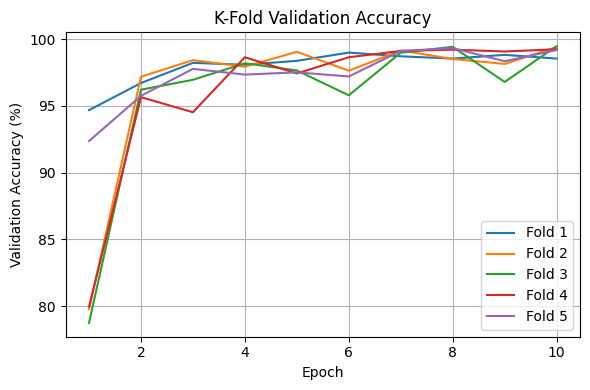

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

for f in folds:
    plt.plot(epochs, folds[f]["val_acc"], label=f"Fold {f}")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("K-Fold Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("kfold_val_accuracy.png", dpi=300)
plt.show()

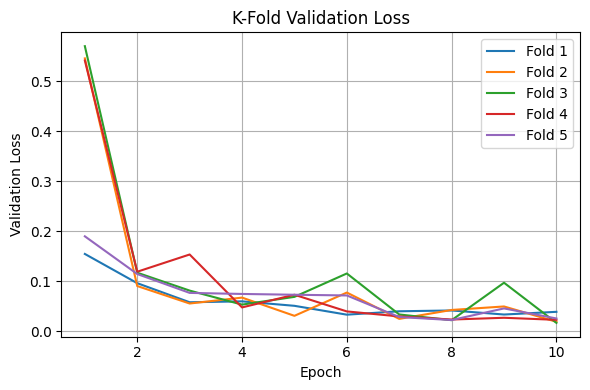

In [3]:
plt.figure(figsize=(6,4))

for f in folds:
    plt.plot(epochs, folds[f]["val_loss"], label=f"Fold {f}")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("K-Fold Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("kfold_val_loss.png", dpi=300)
plt.show()

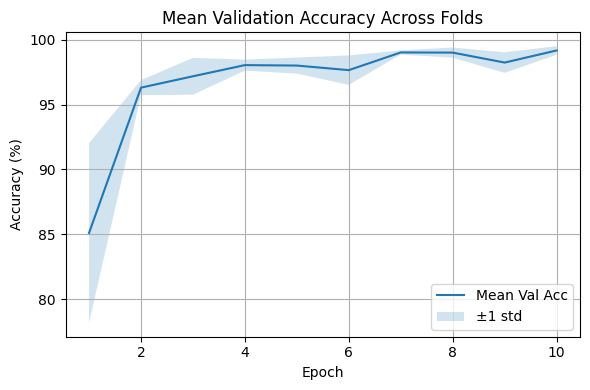

In [4]:
# stack and average
val_acc_all = np.array([folds[f]["val_acc"] for f in folds])
mean_acc = val_acc_all.mean(axis=0)
std_acc = val_acc_all.std(axis=0)

plt.figure(figsize=(6,4))
plt.plot(epochs, mean_acc, label="Mean Val Acc")
plt.fill_between(
    epochs,
    mean_acc - std_acc,
    mean_acc + std_acc,
    alpha=0.2,
    label="±1 std"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Mean Validation Accuracy Across Folds")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("kfold_mean_accuracy.png", dpi=300)
plt.show()

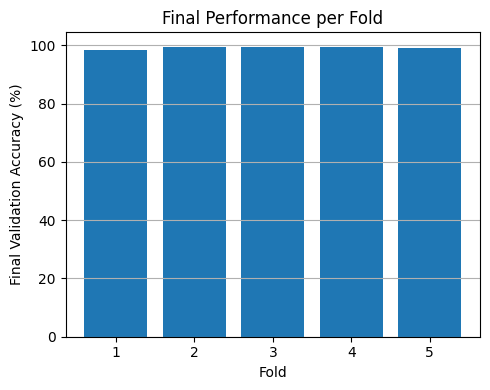

In [5]:
final_vals = [folds[f]["val_acc"][-1] for f in folds]

plt.figure(figsize=(5,4))
plt.bar(range(1,6), final_vals)
plt.xlabel("Fold")
plt.ylabel("Final Validation Accuracy (%)")
plt.title("Final Performance per Fold")
plt.grid(axis="y")
plt.tight_layout()
plt.savefig("kfold_bar.png", dpi=300)
plt.show()